# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

The dataset is related to 17 campaigns that ocurred between May 2008 and November 2010.

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [194]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, TunedThresholdClassifierCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, roc_curve, roc_auc_score
import time

In [63]:
bank_campaings = pd.read_csv('data/bank-additional-full.csv', sep = ';')

In [64]:
bank_campaings.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



In [65]:
bank_campaings.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [66]:
# Let's see the distribution of accepting the offer.
redable_success = bank_campaings[['y']].copy()
redable_success.rename(columns = {'y': 'Subscribed'}, inplace = True)
redable_success.value_counts(normalize=True)*100

Subscribed
no            88.734583
yes           11.265417
Name: proportion, dtype: float64

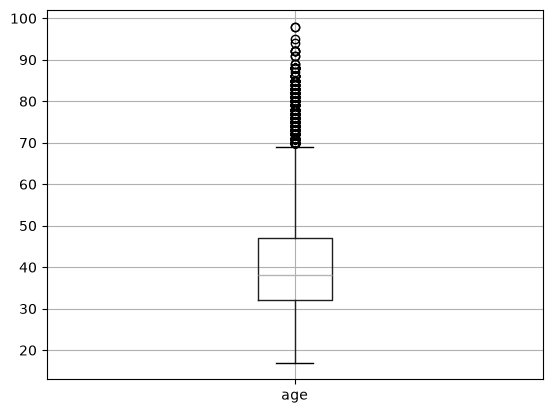

count    41188.00000
mean        40.02406
std         10.42125
min         17.00000
25%         32.00000
50%         38.00000
75%         47.00000
max         98.00000
Name: age, dtype: float64


In [81]:
# Plotting the age column in a boxplot to visualize the age distribution
bank_campaings.boxplot(column = 'age')
plt.show()
print(bank_campaings['age'].describe())

In [68]:
# Grouping the data by job and calculating the acceptance rate of suscription to
# the long-term invesment, to see the distribution of job and accepting
# the offer
readable_job_subscribed = bank_campaings[['job', 'y']].copy()
readable_job_subscribed.rename(columns = {'y': 'Subscribed', 'job': 'Job'}, inplace = True)
job_mapping = {
    'admin.': 'Admin',
    'blue-collar': 'Blue-collar',
    'entrepreneur': 'Entrepreneur',
    'housemaid': 'Housemaid',
    'management': 'Management',
    'retired': 'Retired',
    'self-employed': 'Self-employed',
    'services': 'Services',
    'student': 'Student',
    'technician': 'Technician',
    'unemployed': 'Unemployed',
    'unknown': 'Unknown'
}
readable_job_subscribed['Job'] = readable_job_subscribed['Job'].replace(job_mapping)
readable_job_subscribed.groupby('Job')['Subscribed'].value_counts(normalize=True)*100

Job            Subscribed
Admin          no            87.027442
               yes           12.972558
Blue-collar    no            93.105684
               yes            6.894316
Entrepreneur   no            91.483516
               yes            8.516484
Housemaid      no            90.000000
               yes           10.000000
Management     no            88.782490
               yes           11.217510
Retired        no            74.767442
               yes           25.232558
Self-employed  no            89.514426
               yes           10.485574
Services       no            91.861930
               yes            8.138070
Student        no            68.571429
               yes           31.428571
Technician     no            89.173958
               yes           10.826042
Unemployed     no            85.798817
               yes           14.201183
Unknown        no            88.787879
               yes           11.212121
Name: proportion, dtype: float64

### Missing Values
Based on the result above, it seems none of the columns have missing values.

### Bias in response column
From the bank's data, 88.73% of the customers said no to the long term invesment offer. Only 11.27% said yes. This should be taken into account when training the models and adjusting the performance metrics.

### Coerce Features to a different data type
The pdays column is the number of days since the customer was last contacted. It says value '999' means the client has not been contacted in the past. This value would add noise to modeling. Instead, this column should be replaced with categorical buckets of days since last contacted and one of the buckets should be 'First' for first time being contacted.

As seen below, the data is heavily biased on '999'.

In [69]:
# Output a table of value_counts of pdays to better understand
# the distribution and decide on optimal buckets to analyze the data.
readable_pdays = bank_campaings[['pdays']].copy()
readable_pdays.rename(columns = {'pdays': 'Days since last contact'}, inplace = True)
readable_pdays['Days since last contact'].value_counts().sort_index()

Days since last contact
0         15
1         26
2         61
3        439
4        118
5         46
6        412
7         60
8         18
9         64
10        52
11        28
12        58
13        36
14        20
15        24
16        11
17         8
18         7
19         3
20         1
21         2
22         3
25         1
26         1
27         1
999    39673
Name: count, dtype: int64

### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

Create a classifier model, exploring different techniques, to predict if a client will subscribe a long-term deposit. The model can help design a more efficient campaing that will make the best use of the bank's resources by targeting customers that are more likely to suscribe to a long-term deposit.

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

In [70]:
# Let's remove the duration column since it says in the description
# it should be discarded for purposes of creating a predictive model.
bank_campaings.drop(columns = ['duration'], inplace = True)

# Let's replace the pdays column with a new column 'days_since_last_contact'
# with categories: 'New' for '999', '0 to 3', '4 to 6', '7 or more'.
bank_campaings['days_since_last_contact'] = 'New'
bank_campaings.loc[(bank_campaings['pdays'] >= 7) & (bank_campaings['pdays'] < 999), 'days_since_last_contact'] = '7 or more'
bank_campaings.loc[(bank_campaings['pdays'] >= 4) & (bank_campaings['pdays'] <= 6), 'days_since_last_contact'] = '4 to 6'
bank_campaings.loc[(bank_campaings['pdays'] >= 0) & (bank_campaings['pdays'] <= 3), 'days_since_last_contact'] = '0 to 3'
bank_campaings.drop(columns = ['pdays'], inplace = True)
bank_campaings['days_since_last_contact'].value_counts()

days_since_last_contact
New          39673
4 to 6         576
0 to 3         541
7 or more      398
Name: count, dtype: int64

In [193]:
# Separating the target column
X = bank_campaings.drop(columns = ['y'])
y = bank_campaings['y']

le = LabelEncoder()
y = le.fit_transform(y)

categorical_columns = X.select_dtypes(include=['object', 'str']).columns.tolist()
numerical_columns = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(drop='first'), categorical_columns)
    ])

X_transformed = preprocessor.fit_transform(X)

### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [72]:
X_train, X_test, y_train, y_test = train_test_split(X_transformed, y, test_size=0.2, random_state=21)

### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [73]:
dummy_clf = DummyClassifier().fit(X_train, y_train)
baseline_score = dummy_clf.score(X_test, y_test)

print(f'Dummy Classifier Score: {baseline_score*100:.2f}%')

Dummy Classifier Score: 88.76%


### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [74]:
log_reg = LogisticRegression(max_iter=1000).fit(X_train, y_train)

### Problem 9: Score the Model

What is the accuracy of your model?

In [75]:
log_reg_score = log_reg.score(X_test, y_test)

print(f'Logistic Regression Score: {log_reg_score*100:.2f}%')

Logistic Regression Score: 89.83%


### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [76]:
models_default = {
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'SVM': SVC()
}

def format_time(seconds):
    minutes, seconds = divmod(seconds, 60)
    if minutes > 0:
      return f"{int(minutes)} minutes, {seconds:.2f} seconds"
    else:
      return f"{seconds:.3f} seconds"

results_default = []

for model_name, model in models_default.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time()
    train_time = end_time - start_time

    train_accuracy = model.score(X_train, y_train)
    test_accuracy = model.score(X_test, y_test)

    results_default.append({
        'Model': model_name,
        'Train Time': format_time(train_time),
        'Train Accuracy': f'{train_accuracy*100:.2f}%',
        'Test Accuracy': f'{test_accuracy*100:.2f}%'
    })

results_default_df = pd.DataFrame(results_default)
results_default_df.set_index('Model', inplace=True)
results_default_df

,Train Time,Train Accuracy,Test Accuracy
Model,,,
KNN,0.004 seconds,91.45%,89.14%
Decision Tree,1.252 seconds,99.56%,83.77%
SVM,"1 minutes, 32.49 seconds",90.57%,90.01%


#### Results analysis

The train accuracy is really high, but the test accuracy is not that close. This means the models are overfitting.

### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

#### Strategy

I defined two methods: `grid_search` and `plot_results` to facilitate the training and analysis. 

##### grid_search

The method `grid_search` receives as parameters a dictionary with the model's name and a tuple with the default instances of the corresponding classifiers and its parameter grid that will be used to run `GridSearchCV` for hyperparameter tuning and grid search. 

The method also has `scoring` as parameter, which allows changing the performance metric. This `scoring` parameter is passed to `GridSearchCV` to find the best estimator with the corresponding performance metric. Once `GridSearchCV` has found an estimator, this estimator is passed to a `TunedThresholdClassifierCV` with the same `scoring` parameter to find the right threshold. This last step is needed because by default, classifier estimators use 0.5 as threshold, but with a data as imbalanced as this one, 0.5 is not the most efficient threshold as it will benefit more the class with more elements.

This method returns the train time, train accuracy, test accuracy, best parameters, best threshold and the best estimator.

##### plot_values

Using the information about the best parameters, best threshold and best estimator, this methods output this information an it generates the following plots for each classifier:
- Confusion Matrix
- Precision-Recall
- ROC-AUC Curves

This helps as visual representation of the performance of each classifier.


In [176]:
# Split the data again so a preprocessor can be run in the pipeline and prevent data leakage.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=21)
categorical_columns = X.select_dtypes(include=['object', 'str']).columns.tolist()
numerical_columns = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# I had to add handle_unknown to OneHotEncoder because the 'default' column has a very small amount of yes
# and it was causing an error during training where it said it has never seen 'yes' before.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(min_frequency=10, handle_unknown='infrequent_if_exist', sparse_output=False), categorical_columns)
    ])

# Defining some functions that will be useful to evaluate the models.

def grid_search(models, scoring=None):
  """
  Performs grid search on a dictionary of models and their corresponding parameter grids, 
  allowing to also configure the strategy to evaluate the performance of the cross-validated model on the test set.

  Args:
    models (dict[str, (model, param_grid)]): Dictionary with the model name as key and a tuple of the model and its parameter grid 
                                             for hyperparameter tuning.
    scoring (str) : Stategy to evaluate the cross-validated model on the test set.

  Returns:
    tuple (list[dict[str, str, str, str]], list[dict[str, str, str]]): A tuple containing:
        - results: List of dictionaries containing the results to display of the grid search. Each dictionary contains the following keys:
          - 'Model': The name of the model.
          - 'Train Time': The time it took to train the model.
          - 'Train Accuracy': The accuracy of the model on the training set.
          - 'Test Accuracy': The accuracy of the model on the test set.
        - best_values: List of dictionaries containing:
          - 'Model': The name of the model.
          - 'best_params': The best parameters found by the grid search.
          - 'best_threshold': The best threshold found by the TunedThresholdClassifierCV.
          - 'best_estimator': The estimator that gave the best results.
  """
  results = []
  best_values = []
  for model_name, (model, param_grid) in models.items():
      pipeline = Pipeline([
          ('preprocessor', preprocessor),
          (model_name, model)
      ])
      grid_search = GridSearchCV(pipeline, param_grid=param_grid, cv=5, n_jobs=-1, scoring=scoring, error_score="raise")
      start_time = time.time()
      grid_search.fit(X_train, y_train)
      end_time = time.time()
      train_time = end_time - start_time
      
      train_accuracy = 0
      test_accuracy = 0
      best_threshold = None
      best_model = grid_search.best_estimator_
      
      # Use the right scoring method
      if scoring is None:
          train_accuracy = grid_search.score(X_train, y_train)
          test_accuracy = grid_search.score(X_test, y_test)
      else:
          tuned_clf = TunedThresholdClassifierCV(estimator=grid_search.best_estimator_, scoring=scoring, cv=5)
          # Finding optiomal threshold
          tuned_clf.fit(X_train, y_train)
          train_accuracy = tuned_clf.score(X_train, y_train)
          test_accuracy = tuned_clf.score(X_test, y_test)
          best_model = tuned_clf
          best_threshold = tuned_clf.best_threshold_
          
      results.append({
          'Model': model_name,
          'Train Time': format_time(train_time),
          'Train Accuracy': f'{train_accuracy*100:.2f}%',
          'Test Accuracy': f'{test_accuracy*100:.2f}%',
      })
      best_values.append({
          'Model': model_name,
          'best_params': grid_search.best_params_,
          'best_threshold': best_threshold,
          'best_model': best_model
      })

  return results, best_values

def plot_results(best_values):
    for value in best_values:
        print(
            f"Model: {value['Model']}, Best params: {value['best_params']}, "
            f"Best threshold: {f'{value['best_threshold']:.4f}' if value['best_threshold'] is not None else 'N/A'}")
        # Show Confusion Matrix
        estimator = value['best_model']
        y_pred = estimator.predict(X_test)
        cm = confusion_matrix(y_test, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])
        disp.plot(cmap=plt.cm.Blues)
        plt.title(f'Confusion Matrix ({value['Model']})')
        plt.show()
        # Show Precision-Recall
        y_probs = None
        if value['Model'] == 'SVM':
            y_probs = estimator.decision_function(X_test)
        else:
            y_probs = estimator.predict_proba(X_test)[:, 1]
        precision, recall, thresholds = precision_recall_curve(y_test, y_probs)
        plt.figure(figsize=(6, 4))
        plt.plot(thresholds, precision[:-1], label='Precision', color='blue')
        plt.plot(thresholds, recall[:-1], label='Recall', color='orange')
        plt.xlabel('Probability Threshold')
        plt.ylabel('Score')
        plt.title(f'Precision-Recall Trade-off across Thresholds ({value['Model']})')
        plt.legend()
        plt.grid(True)
        plt.show()
        # Show ROC-AUC Curves
        roc_auc = roc_auc_score(y_test, y_probs)
        fpr, tpr, thresholds = roc_curve(y_test, y_probs)
        plt.figure(figsize=(6, 4))
        plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})', color='purple')
        plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (0.5)')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f'Receiver Operating Characteristic (ROC - {value['Model']})')
        plt.legend(loc='lower right')
        plt.grid(True)
        plt.show()

#### Default scorer

For this analysis, I did not change the performance metric and relied on the default scorer of each classifier. Given that there is an imbalance in the dataset with the number of "Yes" and "No" in customers that accepted the long-term invesment offer, I tried passing different parameters of `class_weight` to SVM and Decision Tree so this imbalance is taking in consideration during traning.

In [174]:
# Grid Search with default scoring of the models.

models = {
    'KNN': (
        KNeighborsClassifier(),
        {
            'KNN__n_neighbors': [29, 30, 31],
            'KNN__weights': ['uniform', 'distance']
        }
    ),
    'SVM': (
        SVC(max_iter=20_000, tol=1e-3),
        {
            'SVM__C': [0.1, 1],
            'SVM__kernel': ['rbf'],
            'SVM__class_weight': ['balanced', {0: 1, 1: 15}],
            'SVM__gamma': ['auto']
        }
    ),
    'DecisionTree': (
        DecisionTreeClassifier(),
        {
            'DecisionTree__max_depth': [None, 1, 5, 7, 9],
            'DecisionTree__min_samples_split': [12, 15, 20, 22],
            'DecisionTree__class_weight': ['balanced', {0: 1, 1: 15}]
        }
    )
}

results_default_scoring, best_values_default = grid_search(models)

results_default_scoring_df = pd.DataFrame(results_default_scoring)
results_default_scoring_df.set_index('Model', inplace=True)
results_default_scoring_df

,Train Time,Train Accuracy,Test Accuracy
Model,,,
KNN,11.546 seconds,90.21%,89.91%
SVM,"5 minutes, 37.18 seconds",83.81%,83.55%
DecisionTree,13.036 seconds,87.47%,87.17%


#### Default scorer: Results

- KNN: Out of the tree, it provided the best test accuracy, but by looking at the confusion matrix, it heavily misclassfied "Yes". The True Positive rate for "Yes" is 21.38%.
- SVM: Based on the Train accuracy and Test Accuracy results, it is not overfitted, but its score is very low (less than the baseline). It did a better jon than KNN in classifying "Yes", with a True positive rate of 61.23% for "Yes". However, false positives for "Yes" also increased, but that is expected.
- Decision Tree: Based on the Train accuracy and Test Accuracy results, it is not overfitted, but its score is very low (less than the baseline). It did a better job than KNN on classifying true "Yes", but performed slightly worse than SVM. The True Positive rate for "Yes" is 40.87%.

Model: KNN, Best params: {'KNN__n_neighbors': 30, 'KNN__weights': 'uniform'}, Best threshold: N/A


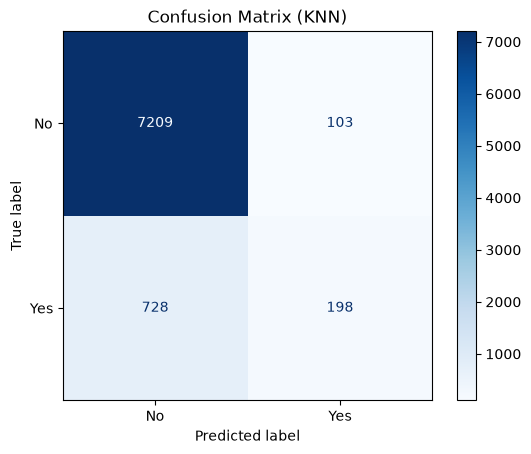

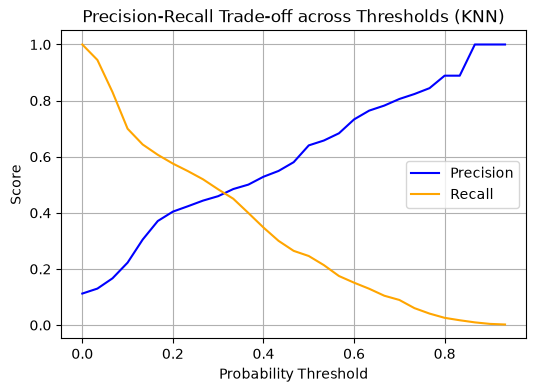

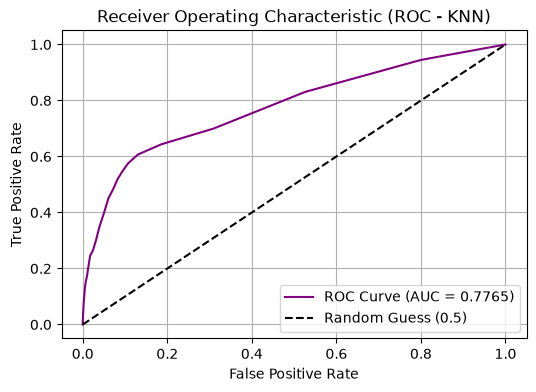

Model: SVM, Best params: {'SVM__C': 1, 'SVM__class_weight': 'balanced', 'SVM__gamma': 'auto', 'SVM__kernel': 'rbf'}, Best threshold: N/A


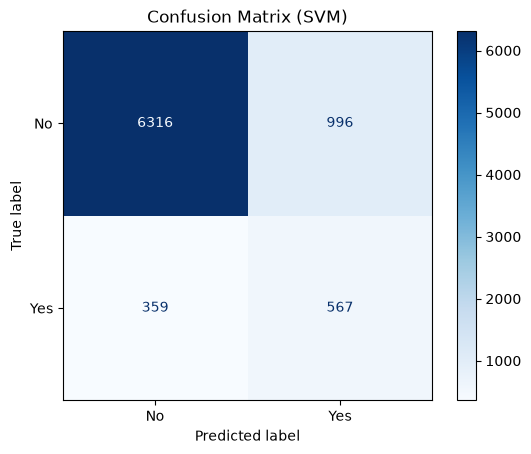

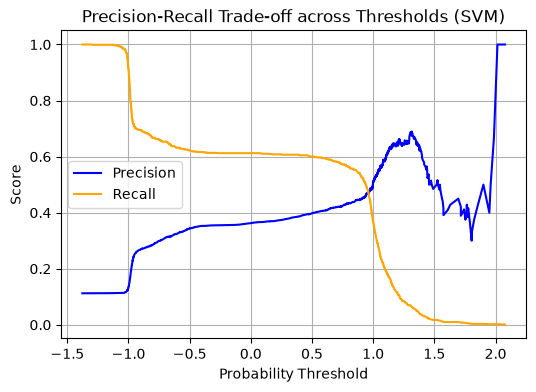

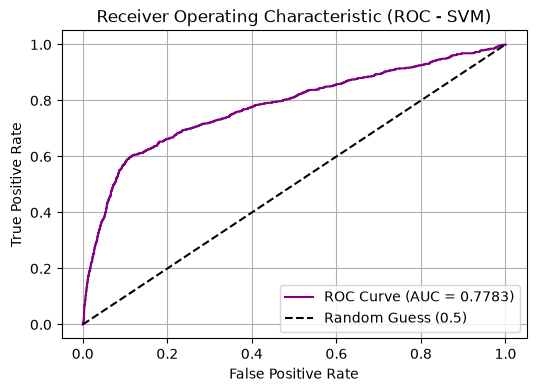

Model: DecisionTree, Best params: {'DecisionTree__class_weight': 'balanced', 'DecisionTree__max_depth': 1, 'DecisionTree__min_samples_split': 12}, Best threshold: N/A


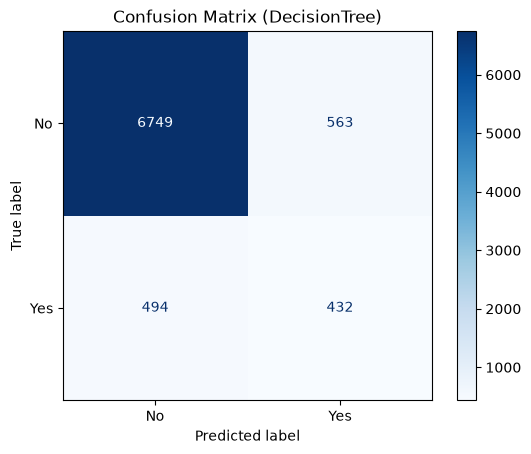

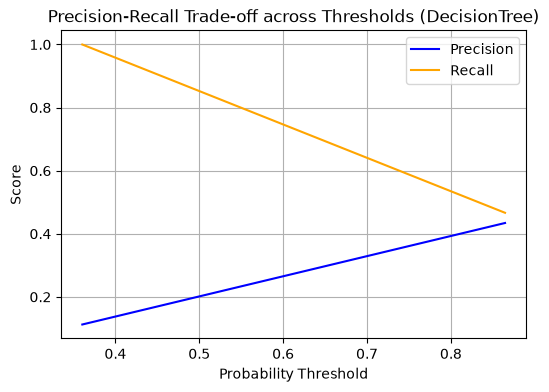

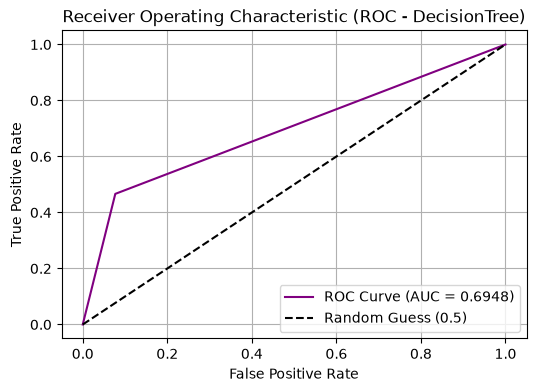

In [177]:
plot_results(best_values_default)

#### F1 Scorer

Here F1 will be used as performance metric for training. In theory, it should perform better since F1 is recommended when data classes are heavily skewed.

In [180]:
# Grid Search with scoring set to 'f1'.
models = {
    'KNN': (
        KNeighborsClassifier(),
        {
            'KNN__n_neighbors': [1, 3, 5, 7],
            'KNN__weights': ['uniform', 'distance']
        }
    ),
    'SVM': (
        SVC(max_iter=20_000, tol=1e-3),
        {
            'SVM__C': [0.1, 1],
            'SVM__kernel': ['rbf'],
            'SVM__class_weight': ['balanced'],
            'SVM__gamma': ['auto']
        }
    ),
    'DecisionTree': (
        DecisionTreeClassifier(),
        {
            'DecisionTree__max_depth': [None, 6, 7, 10, 12],
            'DecisionTree__min_samples_split': [10, 12, 15, 20, 22],
            'DecisionTree__class_weight': ['balanced', {0: 1, 1: 15}]
        }
    )
}

results_f1_scoring, best_values_f1 = grid_search(models, scoring='f1')

results_f1_scoring_df = pd.DataFrame(results_f1_scoring)
results_f1_scoring_df.set_index('Model', inplace=True)
results_f1_scoring_df

,Train Time,Train Accuracy,Test Accuracy
Model,,,
KNN,7.222 seconds,90.06%,86.10%
SVM,"3 minutes, 0.21 seconds",86.94%,86.61%
DecisionTree,23.861 seconds,87.68%,86.95%


#### F1 Scorer: Results

All the models have worse score than the baseline, but the true positive rates improved in some of them:
- KNN: True positive rate of 43.73%.
- SVM: True positive rate of 57.01%
- Decision Tree: True positive rate of 54.53%.


Model: KNN, Best params: {'KNN__n_neighbors': 5, 'KNN__weights': 'uniform'}, Best threshold: 0.2020


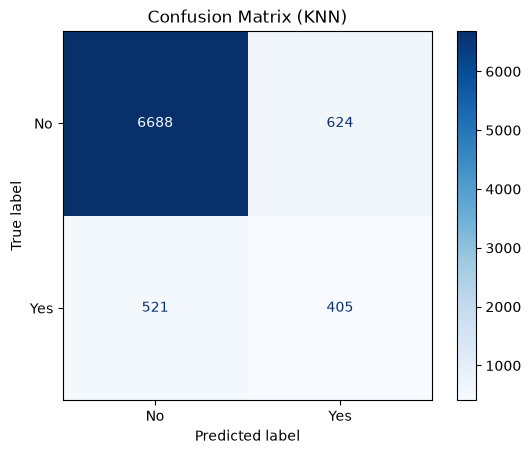

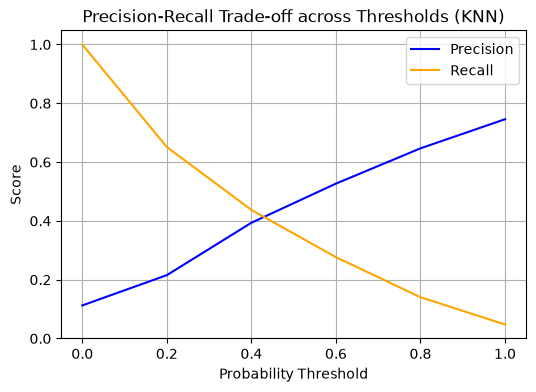

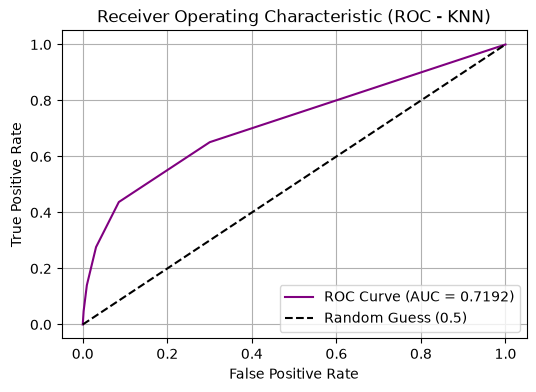

Model: SVM, Best params: {'SVM__C': 1, 'SVM__class_weight': 'balanced', 'SVM__gamma': 'auto', 'SVM__kernel': 'rbf'}, Best threshold: 0.7692


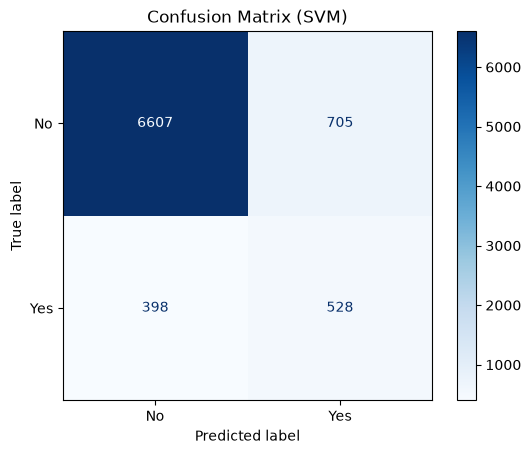

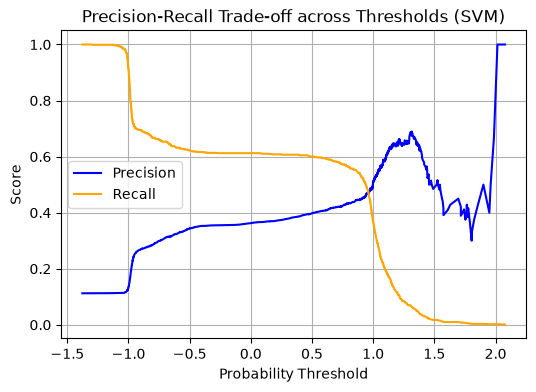

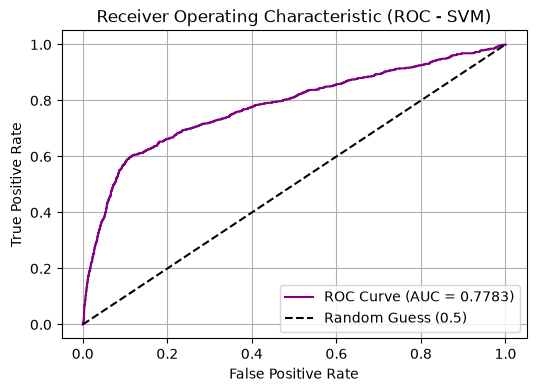

Model: DecisionTree, Best params: {'DecisionTree__class_weight': 'balanced', 'DecisionTree__max_depth': 7, 'DecisionTree__min_samples_split': 22}, Best threshold: 0.6465


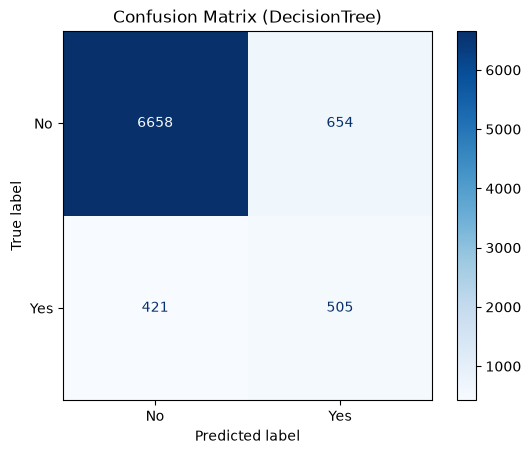

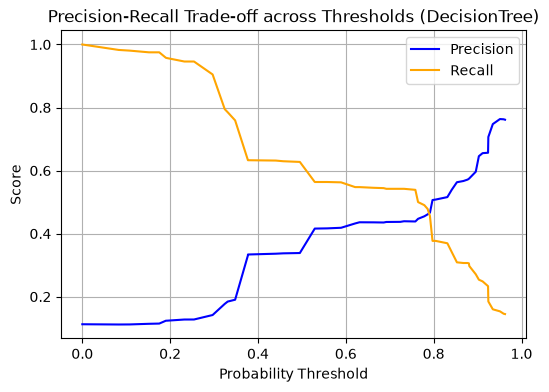

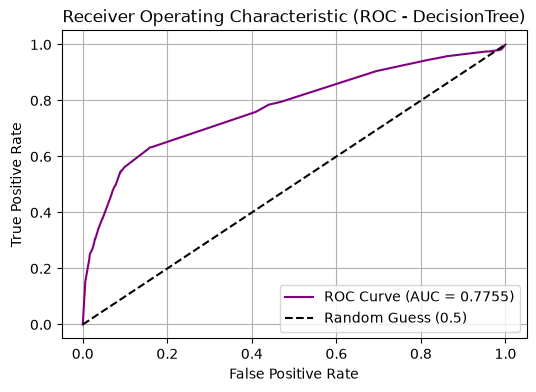

In [181]:
plot_results(best_values_f1)

#### Precision scorer

Precision is used when the cost of false positives if very high. Because of this, I'm not expecting this will help for addressin my goal, but it would be good to check the results for academic purposes.

In [187]:
# Grid Search with scoring set to 'precision'.

models = {
    'KNN': (
        KNeighborsClassifier(),
        {
            'KNN__n_neighbors': [10, 20, 25, 27, 29],
            'KNN__weights': ['uniform', 'distance']
        }
    ),
    'SVM': (
        SVC(max_iter=20_000, tol=1e-3),
        {
            'SVM__C': [0.1, 1, 10],
            'SVM__kernel': ['rbf'],
            'SVM__class_weight': ['balanced', {0: 1, 1: 15}],
            'SVM__gamma': ['auto']
        }
    ),
    'DecisionTree': (
        DecisionTreeClassifier(),
        {
            'DecisionTree__max_depth': [1, 3, 5, 7],
            'DecisionTree__min_samples_split': [10, 12, 15, 20, 22],
            'DecisionTree__class_weight': ['balanced', {0: 1, 1: 15}]
        }
    )
}

results_precision_scoring, best_values_precision = grid_search(models, scoring='precision')

results_precision_scoring_df = pd.DataFrame(results_precision_scoring)
results_precision_scoring_df.set_index('Model', inplace=True)
results_precision_scoring_df

,Train Time,Train Accuracy,Test Accuracy
Model,,,
KNN,16.089 seconds,88.76%,88.82%
SVM,"7 minutes, 7.84 seconds",88.81%,88.78%
DecisionTree,18.880 seconds,87.47%,87.17%


#### Precision scorer: Results

The accuracy is closer to the baseline and the consistency of train accuracy and test accuracy tells me there isn't overfitting. However, the true positive rate for "Yes" is very low.
- KNN: True positive rate of 0.5%
- SVM: True positive rate of 1.07%
- Decision Tree: True positive rate of 46.65%

Model: KNN, Best params: {'KNN__n_neighbors': 20, 'KNN__weights': 'uniform'}, Best threshold: 0.9091


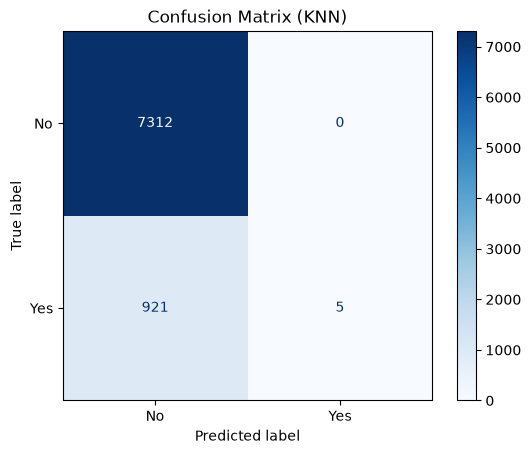

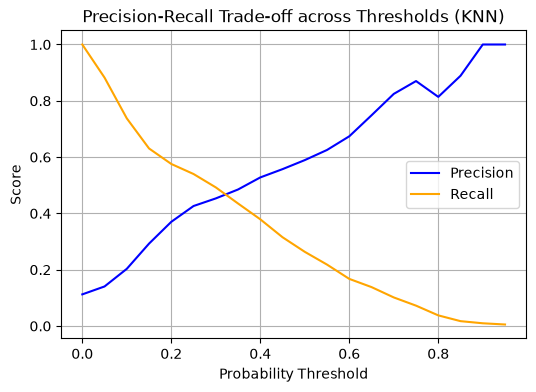

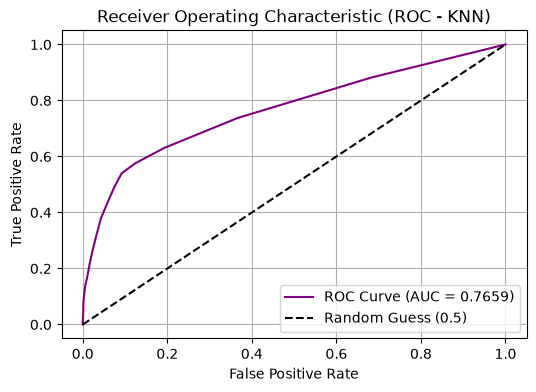

Model: SVM, Best params: {'SVM__C': 10, 'SVM__class_weight': 'balanced', 'SVM__gamma': 'auto', 'SVM__kernel': 'rbf'}, Best threshold: 1.5991


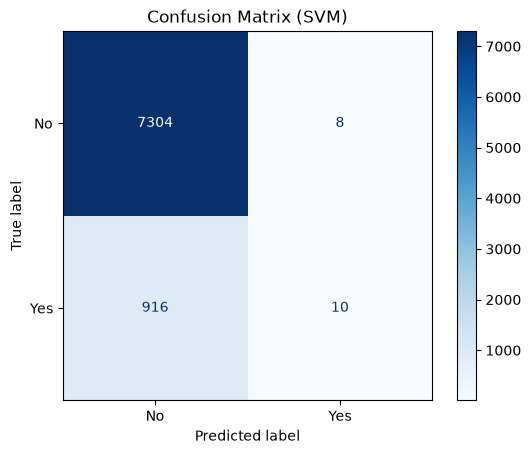

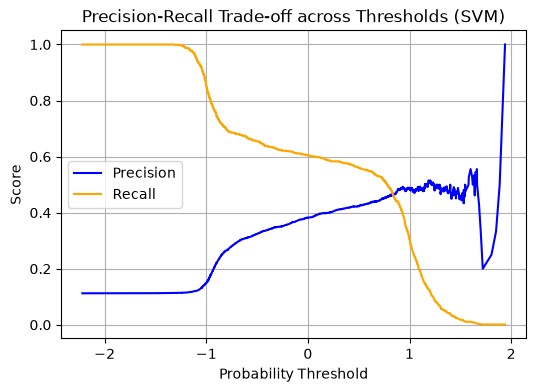

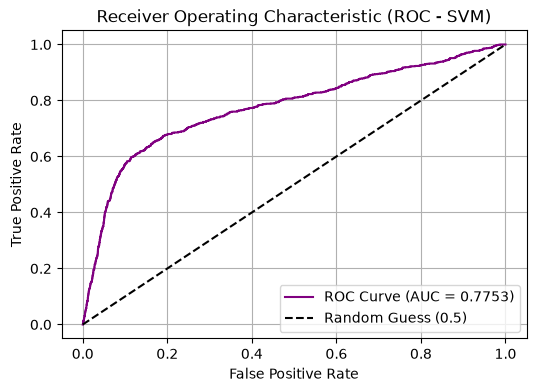

Model: DecisionTree, Best params: {'DecisionTree__class_weight': 'balanced', 'DecisionTree__max_depth': 1, 'DecisionTree__min_samples_split': 10}, Best threshold: 0.3720


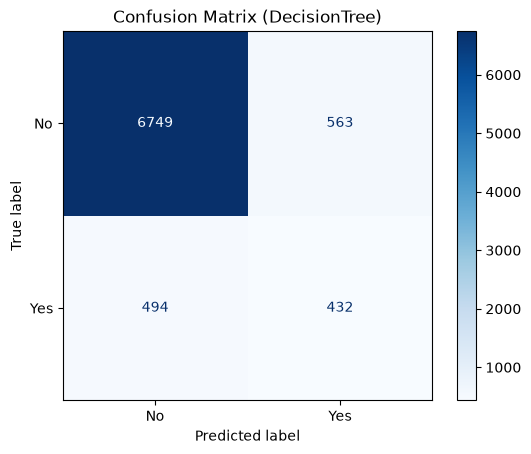

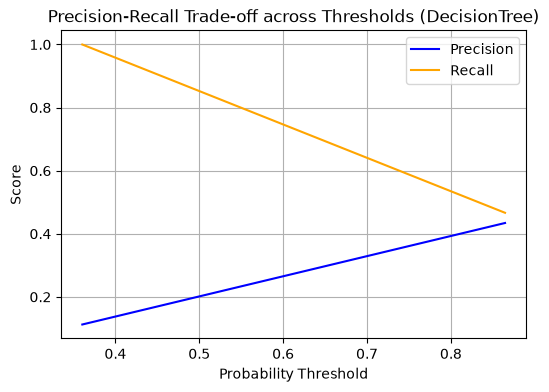

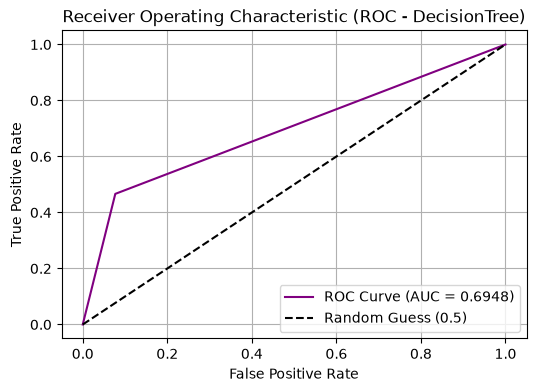

In [188]:
plot_results(best_values_precision)

#### Recall scorer

Recall is used for scoring when false negatives are costly or dangerous. What I'm testing with recall here is to see if it helps with the imbalance of true positives for "Yes" by penalizing more false negatives.

In [189]:
# Grid Search with scoring set to 'recall'.

models = {
    'KNN': (
        KNeighborsClassifier(),
        {
            'KNN__n_neighbors': [1, 2, 3],
            'KNN__weights': ['uniform', 'distance']
        }
    ),
    'SVM': (
        SVC(max_iter=20_000, tol=1e-3),
        {
            'SVM__C': [0.1, 1],
            'SVM__kernel': ['rbf'],
            'SVM__class_weight': ['balanced', {0: 1, 1: 15}],
            'SVM__gamma': ['auto']
        }
    ),
    'DecisionTree': (
        DecisionTreeClassifier(),
        {
            'DecisionTree__max_depth': [None, 1, 3, 5, 7],
            'DecisionTree__min_samples_split': [2, 5, 7],
            'DecisionTree__class_weight': ['balanced', {0: 1, 1: 15}]
        }
    )
}

results_recall_scoring, best_values_recall = grid_search(models, scoring='recall')

results_recall_scoring_df = pd.DataFrame(results_recall_scoring)
results_recall_scoring_df.set_index('Model', inplace=True)
results_recall_scoring_df

,Train Time,Train Accuracy,Test Accuracy
Model,,,
KNN,5.300 seconds,11.27%,11.24%
SVM,"5 minutes, 41.14 seconds",11.27%,11.24%
DecisionTree,15.790 seconds,11.27%,11.24%


#### Recall scorer: Results

The accuracy is extremely bad because, as it is seen below, it increased disproportionally the level of false positives. The true positive rate for "Yes" in all the models is 1, but the false positive rate is also 1.

Model: KNN, Best params: {'KNN__n_neighbors': 1, 'KNN__weights': 'uniform'}, Best threshold: 0.0000


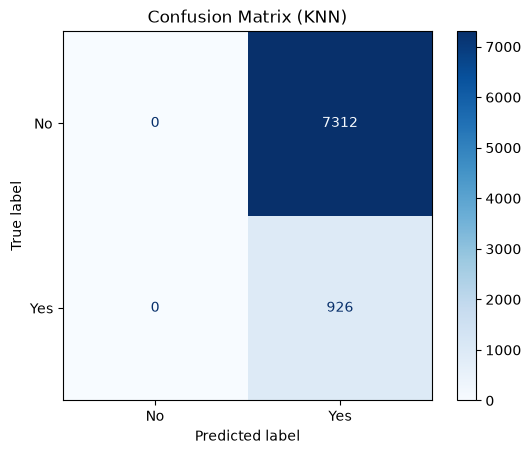

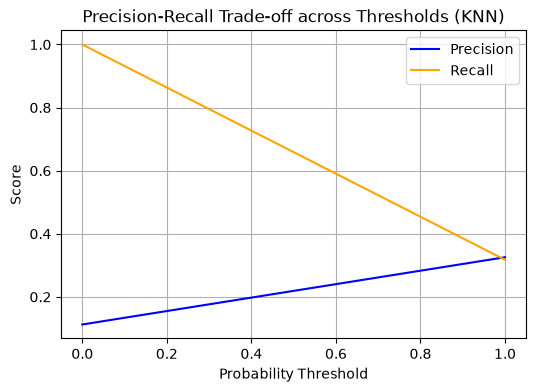

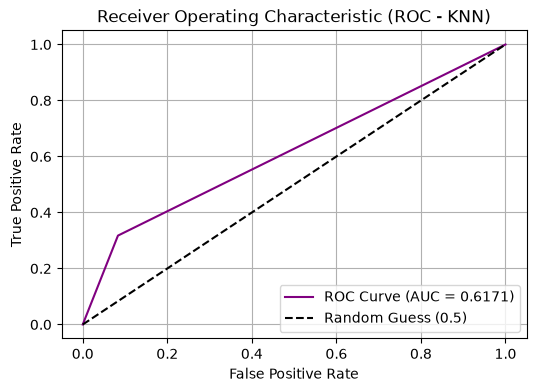

Model: SVM, Best params: {'SVM__C': 0.1, 'SVM__class_weight': {0: 1, 1: 15}, 'SVM__gamma': 'auto', 'SVM__kernel': 'rbf'}, Best threshold: -1.3335


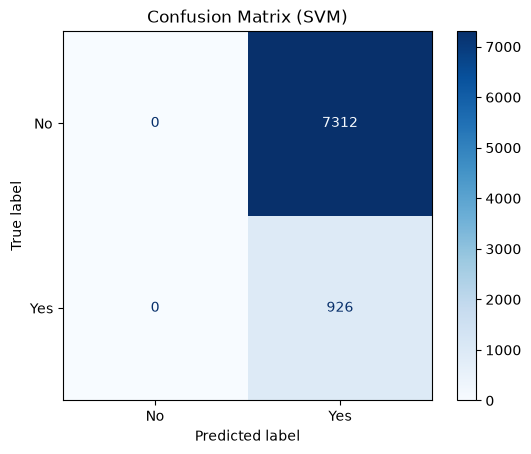

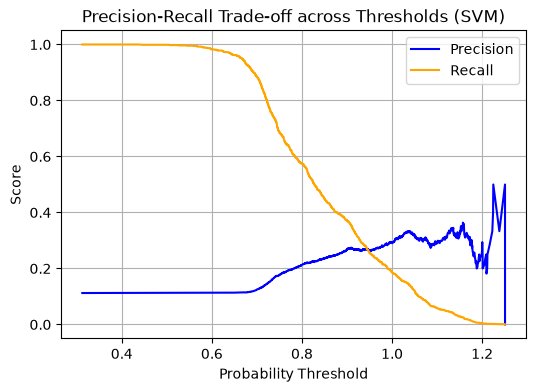

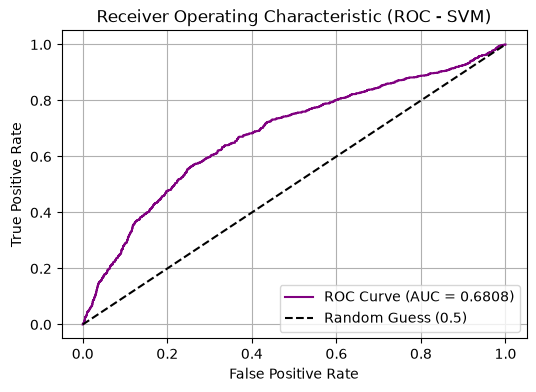

Model: DecisionTree, Best params: {'DecisionTree__class_weight': {0: 1, 1: 15}, 'DecisionTree__max_depth': 7, 'DecisionTree__min_samples_split': 5}, Best threshold: 0.0000


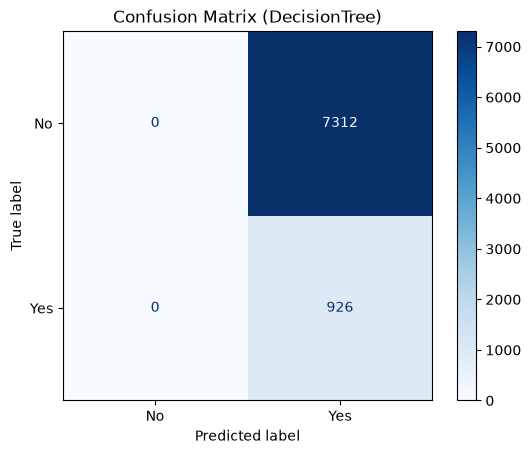

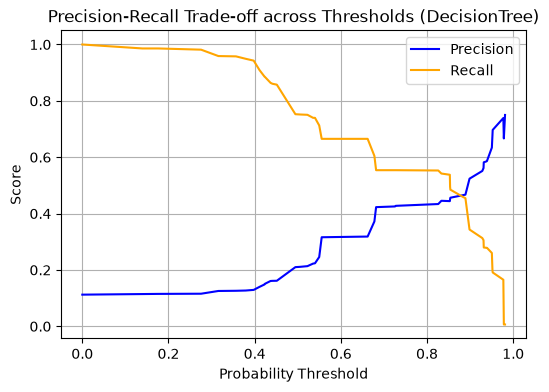

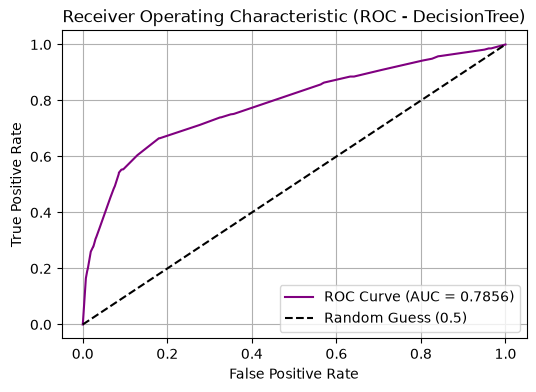

In [190]:
plot_results(best_values_recall)

#### PR-AUC (Area Under the Precision-Recall Curve) scorer

ROC AUC as scoring was also explored, but did not had good results because of the extreme class imbalance (because the positive class is very rare). I removed it from this report because I had already showed two scorers with terrible performance. But, while researching why ROC AUC had a terrible performance, it drived me to find PR-AUC, which is recommended for these cases. 

PR-AUC measures the trade-off between Precision and Recall across various probability thresholds and it is used when there is a heavily imbalanced dataset where the positive class is rare and finding true positives matters most.

To use it in sklearn, the scoring parameter should be set to `average_precision`.

In [191]:
# Grid Search with scoring set to 'average_precision'.

models = {
    'KNN': (
        KNeighborsClassifier(),
        {
            'KNN__n_neighbors': [3, 5, 7],
            'KNN__weights': ['uniform', 'distance']
        }
    ),
    'SVM': (
        SVC(max_iter=20_000, tol=1e-3),
        {
            'SVM__C': [1, 10],
            'SVM__kernel': ['rbf'],
            'SVM__class_weight': ['balanced'],
            'SVM__gamma': ['auto']
        }
    ),
    'DecisionTree': (
        DecisionTreeClassifier(),
        {
            'DecisionTree__max_depth': [5, 7, 9],
            'DecisionTree__min_samples_split': [2, 5, 7],
            'DecisionTree__class_weight': ['balanced', {0: 1, 1: 15}, {0: 1, 1: 20}]
        }
    )
}

results_average_precision_scoring, best_values_average_precision = grid_search(models, scoring='average_precision')

results_average_precision_scoring_df = pd.DataFrame(results_average_precision_scoring)
results_average_precision_scoring_df.set_index('Model', inplace=True)
results_average_precision_scoring_df

,Train Time,Train Accuracy,Test Accuracy
Model,,,
KNN,5.266 seconds,90.39%,88.32%
SVM,"2 minutes, 46.39 seconds",86.94%,86.61%
DecisionTree,16.222 seconds,87.63%,87.24%


#### PR-AUC (Area Under the Precision-Recall Curve) scorer: Results

The accuracy is still less than the baseline, but definitely there is an improvement in the true positive rates.
- KNN: True positive rate 39.30%
- SVM: True positive rate 57.01%
- Decision Tree: True positive rate 54.01%

Model: KNN, Best params: {'KNN__n_neighbors': 7, 'KNN__weights': 'uniform'}, Best threshold: 0.2929


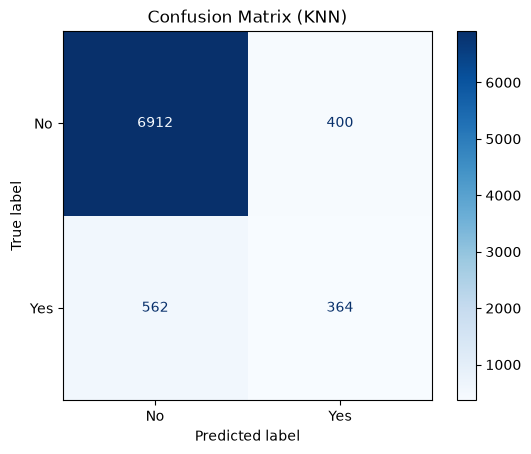

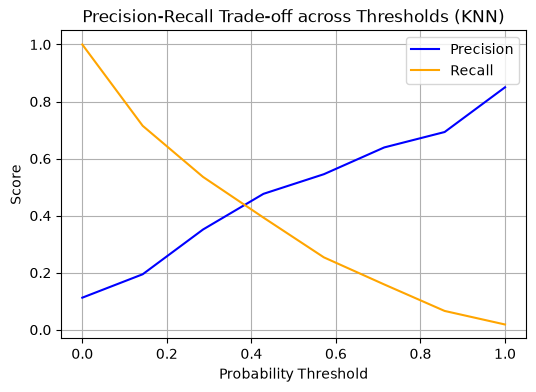

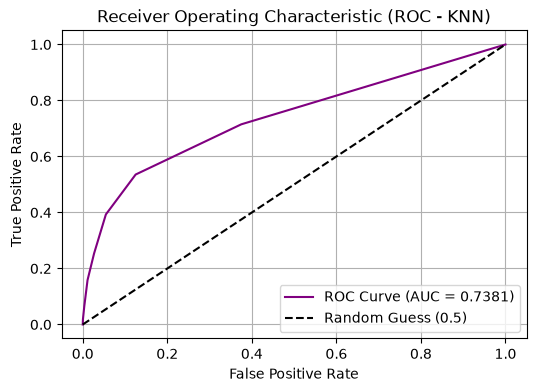

Model: SVM, Best params: {'SVM__C': 1, 'SVM__class_weight': 'balanced', 'SVM__gamma': 'auto', 'SVM__kernel': 'rbf'}, Best threshold: 0.7692


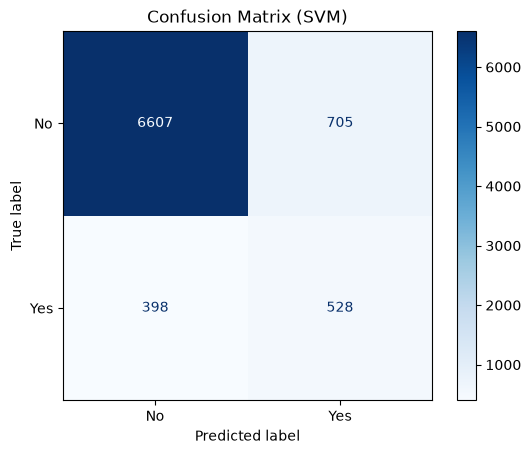

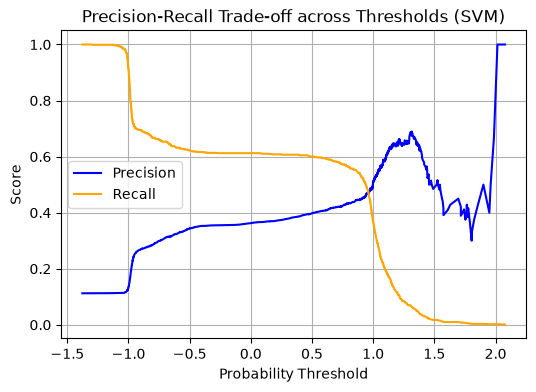

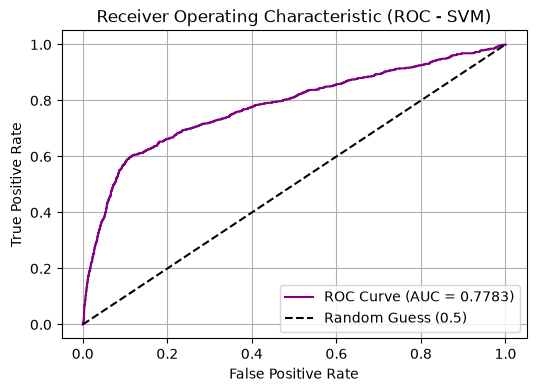

Model: DecisionTree, Best params: {'DecisionTree__class_weight': {0: 1, 1: 15}, 'DecisionTree__max_depth': 7, 'DecisionTree__min_samples_split': 2}, Best threshold: 0.8283


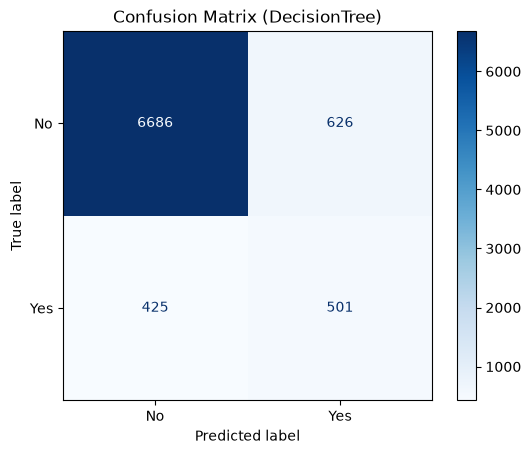

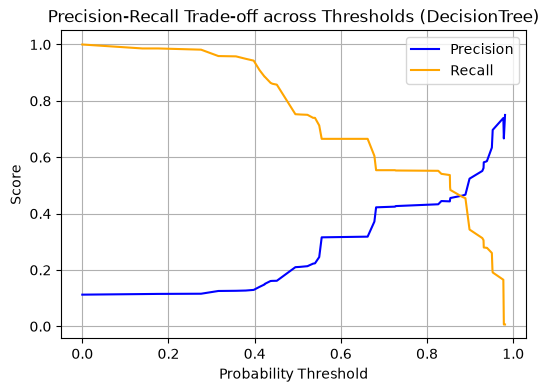

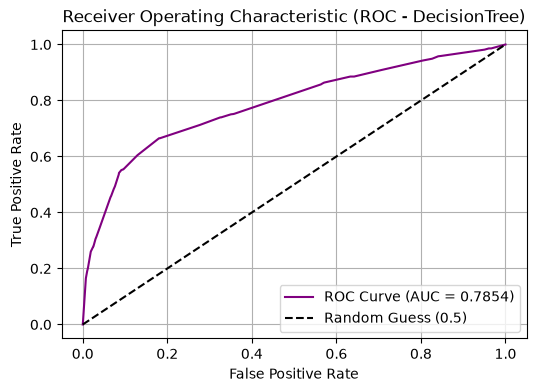

In [192]:
plot_results(best_values_average_precision)

##### Questions